# T1 Solutions: gold-197 neutron capture
### Worked answers to the exercises of section 12 of T1

It uses the same data, the same features and the same error measure (RMS factor and median factor) as T1. Run this notebook from the `notebooks/` folder or the repository root; it needs `scikit-learn`, `xgboost` and `optuna` and takes about two minutes.

**What T1 asked you to learn, and where it is answered here**

| learning outcome of T1 | section of this notebook |
|---|---|
| a tree has settings (hyperparameters) that change its predictions | A |
| choose those settings with a method, not by eye, and score the choice fairly | B |
| compare a tree with a random forest and XGBoost; read feature importances | C |
| give a model more features and ask whether it helps, and what it depends on | D |
| ask how honest a test is (one held-out isotope, look-alikes) | A3, C2, D |

Every error below is an **RMS factor** (1.0 is perfect, 1.3 means typically within 30 %) or a **median factor**, as in T1.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import randint, uniform, loguniform
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from xgboost import XGBRegressor

D = Path("../data/teaching") if Path("../data/teaching").exists() else Path("data/teaching")
db = pd.read_csv(D / "capture_cleaned.csv").merge(pd.read_csv(D / "isotope_features.csv"), on=["Z", "A"])   # the data of T1, with the seven extra features of section 11
ev = pd.read_csv(D / "endf_Au197_capture.csv")
db["logE"], db["logS"] = np.log10(db.energy_eV), np.log10(db.sigma_b * 1000)
db["iso"] = db.Z * 1000 + db.A                       # one number per isotope: used to keep an isotope's points together in cross-validation
features = ["Z", "A", "logE"]
features10 = features + ["N", "Q_capture", "S_n", "B_per_A", "Z_odd", "N_odd", "N_magic_dist"]

def errors(model, df, feats=features):
    r = model.predict(df[feats]) - df.logS           # as in T1: RMS factor and median factor
    return 10 ** np.sqrt(np.mean(r ** 2)), 10 ** np.median(np.abs(r))

def split(Z, A):                                     # hold out one isotope
    t = db[(db.Z == Z) & (db.A == A)]
    return db.drop(t.index), t

train, test = split(79, 197)                         # gold-197, as in T1
E = np.logspace(5, np.log10(2e7), 400); grid = pd.DataFrame({"Z": 79, "A": 197, "logE": np.log10(E)})

# A. Hyperparameters (solutions to 12A)

## A1. Depth and leaf size
We train the tree of T1 again with different `max_depth` and `min_samples_leaf` (everything else as in T1, gold held out), and print the error on gold. We also print the error on the **training points**, and the error on **whole isotopes held out of the training** (cross-validation by isotope, as in section B), to compare what the tree has memorised with what it can predict for isotopes it has not seen.

max_depth  gold RMS  gold median  training RMS  training median  other isotopes RMS
        1      3.70         3.88          5.49             2.95                6.06
        2      2.23         1.76          4.41             2.38                5.84
        3      1.67         1.45          3.63             2.12                4.40
        4      1.65         1.63          3.23             1.91                4.51
        6      1.39         1.31          2.61             1.59                3.79
        8      1.29         1.15          2.11             1.34                4.47
       12      1.32         1.26          1.65             1.16                4.71
     none      1.66         1.66          1.55             1.11                4.96

min_samples_leaf  gold RMS  gold median  training RMS  training median  other isotopes RMS
               1      1.71         1.60          1.15             1.00                5.05
               5      1.66         1.66          1.55        

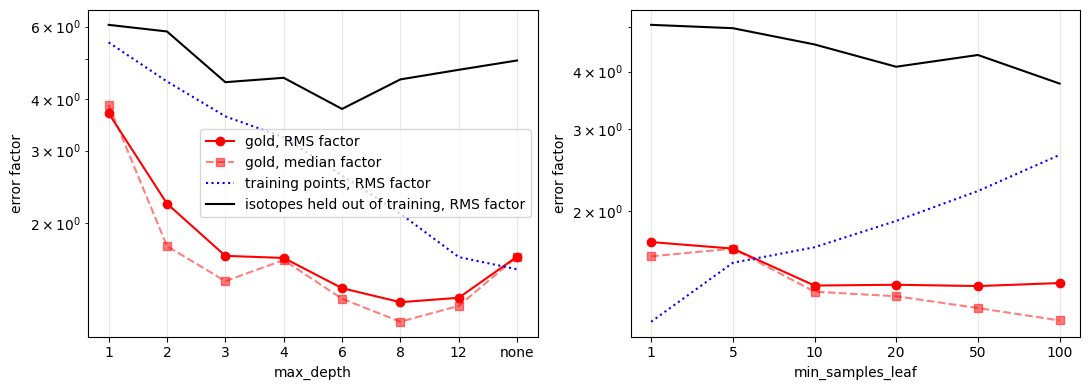

In [2]:
def sweep(name, settings):
    rows = []
    for s in settings:
        m = DecisionTreeRegressor(random_state=0, **s).fit(train[features], train.logS)
        val = 10 ** np.sqrt(-cross_val_score(DecisionTreeRegressor(random_state=0, **s), train[features], train.logS, groups=train.iso, cv=GroupKFold(5), scoring="neg_mean_squared_error").mean())      # error on isotopes held out of the training (5 folds)
        rows.append([str(s[name]).replace("None", "none"), *errors(m, test), *errors(m, train), val])
    return pd.DataFrame(rows, columns=[name, "gold RMS", "gold median", "training RMS", "training median", "other isotopes RMS"])

by_depth = sweep("max_depth", [dict(max_depth=d, min_samples_leaf=5) for d in [1, 2, 3, 4, 6, 8, 12, None]])
by_leaf = sweep("min_samples_leaf", [dict(max_depth=None, min_samples_leaf=l) for l in [1, 5, 10, 20, 50, 100]])
print(by_depth.round(2).to_string(index=False)); print(); print(by_leaf.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, t in zip(ax, [by_depth, by_leaf]):
    x = range(len(t)); a.plot(x, t["gold RMS"], "ro-", label="gold, RMS factor"); a.plot(x, t["gold median"], "rs--", alpha=0.5, label="gold, median factor"); a.plot(x, t["training RMS"], "b:", label="training points, RMS factor"); a.plot(x, t["other isotopes RMS"], "k-", label="isotopes held out of training, RMS factor")
    a.set(xticks=x, xticklabels=t.iloc[:, 0].astype(str), xlabel=t.columns[0], ylabel="error factor", yscale="log"); a.grid(alpha=0.3)
ax[0].legend(); plt.tight_layout()

**Answer.**

* **The training error (blue, dotted) keeps falling as the tree gets bigger**: from 5.5 at depth 1 to 1.55 with no limit, and to 1.15 with leaves of one point. A bigger tree always fits the points it has seen better.
* **The error on isotopes the tree has not seen (black) does not keep falling.** It is the error of the same tree on whole isotopes held out of training (five-fold cross-validation, as in section B). It improves down to 3.8 at depth 6 and then rises again, to 5.0 with no limit. **This is overfitting: the training error falls while the error on new isotopes rises, and it is the widening gap between the blue and the black line that measures it** (1.55 against 5.0 for the unlimited tree). Beyond depth 6 the tree is learning the details of the isotopes it has seen, which do not carry over to others.
* **Gold (red) is not a good guide to this.** It lies *below* the other two lines: gold is an easy isotope, easier than the typical isotope (section A3), so its error is smaller than the training error of the whole table. Its minimum is at depth 8 (1.29), not at depth 6, and its curve is bumpy (1.67, 1.65, 1.39, 1.29, 1.32, 1.66 for depths 3, 4, 6, 8, 12 and no limit). A tree changes in jumps when its settings change, and gold is a single isotope. Do not over-read one bump, and do not judge overfitting from the gap to the red line.
* **Leaf size** (right). Larger leaves make the training error rise (1.15 to 2.6) because the tree is forced to average instead of memorise, and the error on new isotopes *fall* (5.1 to 3.8). Gold is 1.7 with leaves of 1 or 5 points and 1.4 with 10 to 100. Larger leaves cost nothing on gold and give a simpler tree that is better on new isotopes.

## A2. A different loss: `absolute_error`
Same tree (depth 8, leaf 5) with `criterion="squared_error"` and with `"absolute_error"`.

squared_error   gold RMS factor 1.29, median factor 1.15, training time 0.015 s
absolute_error  gold RMS factor 1.35, median factor 1.28, training time 0.128 s


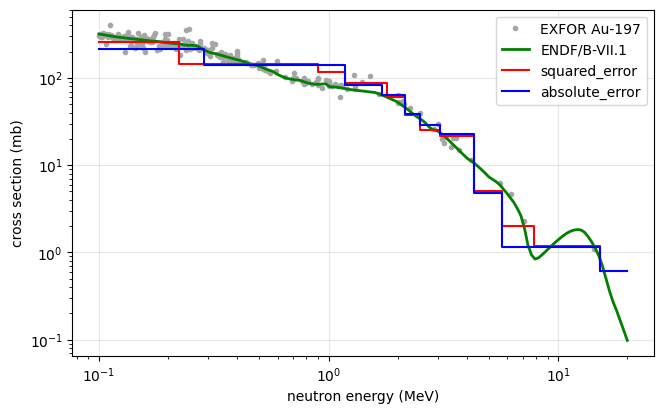

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(test.energy_eV / 1e6, test.sigma_b * 1000, ".", color="0.65", label="EXFOR Au-197"); ax.plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, "g-", lw=2, label="ENDF/B-VII.1")
for crit, c in [("squared_error", "r"), ("absolute_error", "b")]:
    t0 = time.time(); m = DecisionTreeRegressor(criterion=crit, max_depth=8, min_samples_leaf=5, random_state=0).fit(train[features], train.logS); sec = time.time() - t0
    print(f"{crit:15s} gold RMS factor {errors(m, test)[0]:.2f}, median factor {errors(m, test)[1]:.2f}, training time {sec:.3f} s")
    ax.plot(E / 1e6, 10 ** m.predict(grid), c, drawstyle="steps-mid", label=crit)
ax.set(xscale="log", yscale="log", xlabel="neutron energy (MeV)", ylabel="cross section (mb)"); ax.legend(); ax.grid(alpha=0.3)

**Answer.** The two curves are almost the same. The `absolute_error` tree makes each leaf predict the **median** of its points instead of the mean, so it is less pulled by a few wild points. Here it is slightly *worse* on gold (RMS factor 1.29 to 1.35, median factor 1.15 to 1.28) and about 10 times slower to train. Our data were cleaned of wild points, so there is nothing for the median to protect against. On raw EXFOR data the result could differ.

## A3. Other held-out isotopes: is gold easier or harder?
The tree of T1 (depth 8, leaf 5) with each of several isotopes held out in turn.

In [4]:
rows = []
for name, (Z, A) in {"Au-197 (gold)": (79, 197), "U-238": (92, 238), "Ta-181": (73, 181), "Rh-103": (45, 103), "Ag-107": (47, 107), "I-127": (53, 127), "Ne-22": (10, 22)}.items():
    tr, te = split(Z, A)
    m = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0).fit(tr[features], tr.logS)
    rows.append([name, len(te), *errors(m, te)])
print(pd.DataFrame(rows, columns=["held-out isotope", "points", "RMS factor", "median factor"]).round(2).to_string(index=False))

held-out isotope  points  RMS factor  median factor
   Au-197 (gold)     300        1.29           1.15
           U-238     300        1.59           1.33
          Ta-181     190        1.60           1.30
          Rh-103     108        2.17           1.36
          Ag-107      39        1.79           1.56
           I-127     163       39.24          53.38
           Ne-22      98       73.89          19.85


**Answer.** Gold is one of the easier cases. Uranium-238 (1.6), tantalum-181 (1.6), silver-107 (1.8) and rhodium-103 (2.2) are heavy isotopes whose curves resemble gold's, and the tree predicts them as well. But **iodine-127 is off by a factor of 39 and neon-22 by 74**. The error depends enormously on *which* isotope is held out: a result on gold says little about an isotope that is different from everything in the training set.

# B. Choosing the hyperparameters by optimisation (solutions to 12B)

## B1. Grid search, random search and optuna
Three ways of choosing `max_depth` and `min_samples_leaf`, each scored in the same way:

* **Whole isotopes are held out in the validation** (`GroupKFold`, five folds, the isotope as the group). If points of the same isotope were in training and validation, the search would favour a tree that memorises (T1 section 4).
* The score is the **mean squared error of log10 σ**, the loss the tree minimises (`neg_mean_squared_error`), converted back to a factor so that it can be compared with the gold error.
* The search never sees gold: it only uses the training isotopes.

In [5]:
cv = GroupKFold(5)                                   # five folds; the points of an isotope always stay in the same fold
groups = train.iso
score = "neg_mean_squared_error"                     # the same yardstick as the training loss
to_factor = lambda s: 10 ** np.sqrt(-s)              # a CV score back to an RMS factor

hand = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0)
grid_s = GridSearchCV(DecisionTreeRegressor(random_state=0), dict(max_depth=[2, 3, 4, 5, 6, 8, 10, 12], min_samples_leaf=[1, 5, 10, 20, 50]), cv=cv, scoring=score)
rand_s = RandomizedSearchCV(DecisionTreeRegressor(random_state=0), dict(max_depth=randint(2, 16), min_samples_leaf=randint(1, 60)), n_iter=40, cv=cv, scoring=score, random_state=0)
rows = [["hand-chosen", hand.get_params()["max_depth"], hand.get_params()["min_samples_leaf"],
         to_factor(cross_val_score(hand, train[features], train.logS, groups=groups, cv=cv, scoring=score).mean()), *errors(hand.fit(train[features], train.logS), test)]]
for name, s in [("grid search", grid_s), ("random search", rand_s)]:
    s.fit(train[features], train.logS, groups=groups)
    rows.append([name, s.best_params_["max_depth"], s.best_params_["min_samples_leaf"], to_factor(s.best_score_), *errors(s.best_estimator_, test)])

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(t):
    m = DecisionTreeRegressor(max_depth=t.suggest_int("max_depth", 2, 15), min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 60), random_state=0)
    return -cross_val_score(m, train[features], train.logS, groups=groups, cv=cv, scoring=score).mean()
study = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=0)); study.optimize(objective, n_trials=40)
p = study.best_params; best = DecisionTreeRegressor(random_state=0, **p).fit(train[features], train.logS)
rows.append(["optuna", p["max_depth"], p["min_samples_leaf"], to_factor(-study.best_value), *errors(best, test)])
print(pd.DataFrame(rows, columns=["method", "max_depth", "min_samples_leaf", "CV factor (other isotopes)", "gold RMS factor", "gold median factor"]).round(2).to_string(index=False))

       method  max_depth  min_samples_leaf  CV factor (other isotopes)  gold RMS factor  gold median factor
  hand-chosen          8                 5                        4.47             1.29                1.15
  grid search          6                20                        3.68             1.39                1.31
random search          5                25                        3.75             1.42                1.37
       optuna          6                24                        3.68             1.39                1.31


**Answer.**

* **The three methods choose almost the same tree**: depth 5 or 6, with a leaf of 20 to 25 points. The cross-validation factor improves from 4.5 (hand-chosen) to 3.7.
* **But the error on gold gets slightly worse**, from 1.29 to 1.39 to 1.42. This is not a contradiction. The cross-validation score is the average over many isotopes, which are mostly harder than gold; the gold error is one easy isotope. The settings that are best on average are not necessarily best for one isotope, and gold happens to prefer the hand-chosen tree. **An optimiser optimises what you give it**, here the average over the other isotopes.
* **Do the methods agree because the answer is optimal?** They agree because they use the same folds and the same score, so they find the same minimum of the *same* noisy curve. That does not prove the setting is best for a new isotope. Also, the best score of a search is the best of many tries and therefore slightly optimistic; a fair estimate needs the search to be repeated inside an outer loop that holds out isotopes.
* Random search and optuna are cheaper than a grid when there are many settings; with two settings they are no better. Use the cheapest method that gets within the noise.

# C. Compare a tree, a random forest and XGBoost (solutions to 12C)
## C1. On gold, default and tuned
Each model is trained on the same isotopes (not gold), first with its default settings, then with settings found by a random search (30 tries, the same validation as in B). We print the error on gold, the training time, and plot the three tuned predictions next to the measurements and the evaluation, with the feature importances.

In [6]:
spaces = {
    "tree":   (DecisionTreeRegressor(random_state=0), dict(max_depth=randint(2, 16), min_samples_leaf=randint(1, 60))),
    "forest": (RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1), dict(max_depth=randint(3, 25), min_samples_leaf=randint(1, 40), max_features=uniform(0.34, 0.66))),
    "xgboost": (XGBRegressor(random_state=0, n_jobs=-1), dict(n_estimators=randint(50, 400), max_depth=randint(2, 8), learning_rate=loguniform(0.02, 0.3), subsample=uniform(0.5, 0.5), min_child_weight=randint(1, 20))),
}
models, rows = {}, []
for name, (model, space) in spaces.items():
    t0 = time.time(); default = model.fit(train[features], train.logS); t_default = time.time() - t0
    t0 = time.time(); search = RandomizedSearchCV(model, space, n_iter=30, cv=cv, scoring=score, random_state=0).fit(train[features], train.logS, groups=groups); t_search = time.time() - t0
    models[name] = search.best_estimator_
    rows.append([name, *errors(default, test), *errors(search.best_estimator_, test), t_default, t_search])
table_c = pd.DataFrame(rows, columns=["model", "default RMS", "default median", "tuned RMS", "tuned median", "default fit (s)", "tuning (s)"]).set_index("model")
print(table_c.round(2).to_string())

         default RMS  default median  tuned RMS  tuned median  default fit (s)  tuning (s)
model                                                                                     
tree            1.71            1.60       1.42          1.37             0.03        1.95
forest          1.61            1.56       1.31          1.24             0.35       45.50
xgboost         1.58            1.52       1.21          1.09             0.11       35.23


      tree  forest  xgboost
Z     0.82    0.51     0.70
A     0.05    0.35     0.08
logE  0.13    0.13     0.22


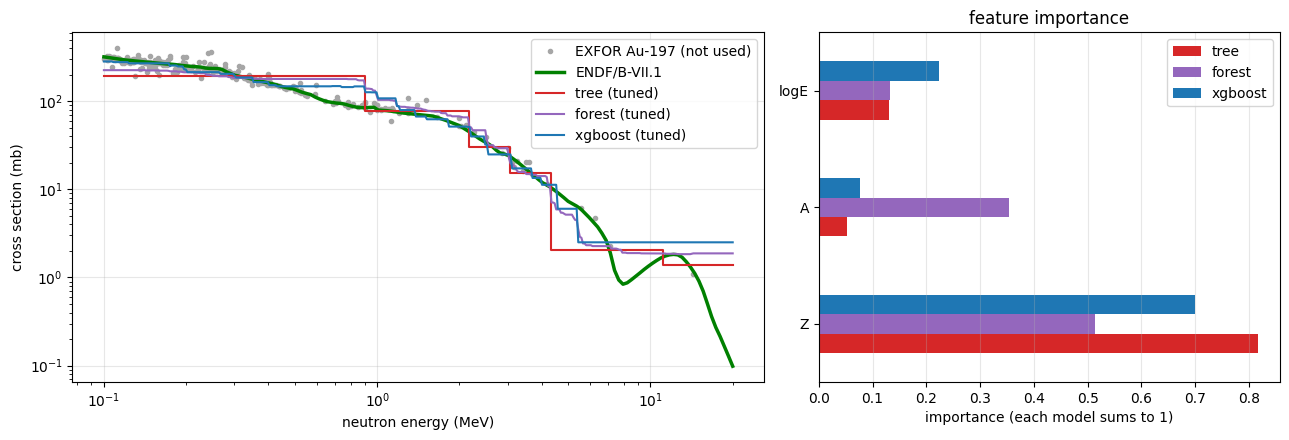

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})
ax[0].plot(test.energy_eV / 1e6, test.sigma_b * 1000, ".", color="0.65", label="EXFOR Au-197 (not used)"); ax[0].plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, "g-", lw=2.5, label="ENDF/B-VII.1")
for (name, m), c in zip(models.items(), ["tab:red", "tab:purple", "tab:blue"]):
    ax[0].plot(E / 1e6, 10 ** m.predict(grid), color=c, drawstyle="steps-mid" if name == "tree" else "default", label=f"{name} (tuned)")
ax[0].set(xscale="log", yscale="log", xlabel="neutron energy (MeV)", ylabel="cross section (mb)"); ax[0].legend(); ax[0].grid(alpha=0.3)
imp = pd.DataFrame({k: m.feature_importances_ for k, m in models.items()}, index=features)
imp.plot.barh(ax=ax[1], color=["tab:red", "tab:purple", "tab:blue"]); ax[1].set(xlabel="importance (each model sums to 1)", title="feature importance"); ax[1].grid(alpha=0.3, axis="x")
plt.tight_layout(); print(imp.round(2).to_string())

**Answer.**

| gold-197 | default | tuned | tuning time |
|---|---|---|---|
| decision tree | 1.71 | 1.42 | 2 s |
| random forest | 1.61 | 1.31 | 47 s |
| XGBoost | 1.58 | 1.21 | 20 s |

* **Tuning helps all three on gold**, by 17 to 23 %, and **XGBoost is the best** (typical error 9 %, median factor 1.09). The default tree is the worst: with no limits it memorises.
* **The price of the better models is time and readability.** The forest takes 20 times longer to tune than the tree. A tree can be drawn and read (T1 section 8); the forest and XGBoost cannot, so we explain them through importances.
* **In the plot** all three follow the evaluation at low energy. At the highest energies (above about 7 MeV) they are flat steps or lines and stay too high, because tree-based models cannot extrapolate; there are few measurements of gold there, so the score hardly sees it.
* **Feature importance.** All three rely mainly on Z (0.5 to 0.8), then on the energy (0.1 to 0.2). The forest also gives A 0.35 while the tree gives it 0.05. Z and A carry nearly the same information (heavier nuclei have both more protons and a larger A), so a model can credit either and the split between them is not meaningful. What is robust: the models use mostly the *identity of the isotope* to place the curve and a little the energy to bend it.

## C2. Is the comparison the same for other isotopes?
One isotope is a small sample. We repeat the comparison with ten different held-out isotopes. To keep it simple the settings are fixed (tree: depth 8, leaf 5; forest and XGBoost: defaults), not tuned. Tuning each model for each held-out isotope fairly needs an extra outer loop.

In [8]:
fixed = {"tree": lambda: DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0), "forest": lambda: RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1), "xgboost": lambda: XGBRegressor(random_state=0, n_jobs=-1)}
isotopes = {"Au-197": (79, 197), "U-238": (92, 238), "Ta-181": (73, 181), "Rh-103": (45, 103), "Ag-107": (47, 107), "W-186": (74, 186), "Hf-178": (72, 178), "Gd-158": (64, 158), "Ba-138": (56, 138), "I-127": (53, 127)}
rows = []
for name, (Z, A) in isotopes.items():
    tr, te = split(Z, A)
    rows.append([name] + [errors(mk().fit(tr[features], tr.logS), te)[0] for mk in fixed.values()])
cmp_ = pd.DataFrame(rows, columns=["held-out isotope", *fixed]).set_index("held-out isotope")
print(cmp_.round(2).to_string())
print("\ngeometric mean over these isotopes:", np.exp(np.log(cmp_).mean()).round(2).to_dict())
print("number of isotopes where each model is the best:", cmp_.idxmin(axis=1).value_counts().to_dict())

                   tree  forest  xgboost
held-out isotope                        
Au-197             1.29    1.61     1.58
U-238              1.59    2.03     1.45
Ta-181             1.60    4.04     3.80
Rh-103             2.17    2.09     7.65
Ag-107             1.79    1.67     1.60
W-186              2.54    3.09     2.62
Hf-178             2.02   10.55    10.37
Gd-158             2.24    1.65     1.65
Ba-138             3.38    2.90    27.24
I-127             39.24   42.23     2.22

geometric mean over these isotopes: {'tree': 2.68, 'forest': 3.53, 'xgboost': 3.51}
number of isotopes where each model is the best: {'tree': 4, 'xgboost': 4, 'forest': 2}


**Answer.** **No model is best everywhere.** The tree has the best geometric mean (2.7, against 3.5 for both the forest and XGBoost) and is best on four isotopes, XGBoost on four, the forest on two. The ranking changes from isotope to isotope, and the differences between isotopes are much larger than those between models: iodine-127 is predicted with an error of 39 by the tree and 42 by the forest but 2.2 by XGBoost; hafnium-178 with 10 by the forest and XGBoost but 2.0 by the tree; barium-138 with 27 by XGBoost but 3 by the others. So **gold alone cannot rank the models**, and the XGBoost result on gold (the best there) did not carry over.

Which curve would you trust as an evaluator? Not one blindly. The tuned XGBoost or forest is a little better on gold, but untuned they are no better than a simple tree, and all of them can fail badly on an isotope unlike the training set. Whatever the model, compare it with the evaluation or with measurements, and ask which isotopes it resembles the target to. The simple tree is the easiest to explain; a more complex model is worth its cost only if it is tuned and checked on many isotopes.

## D. Ten features
The ten features of T1 section 11 (Z, A, log E and seven properties of the isotope: N, Q_capture, S_n, B_per_A, Z_odd, N_odd, N_magic_dist). The three models keep the settings found in C1 and are trained with ten features, gold held out. Then the look-alike test of T1 section 10: the same models trained without the 24 isotopes whose curves lie within a factor of 2 of gold's.

In [9]:
rows = []
for name, m in [("tree", models["tree"]), ("forest", models["forest"]), ("xgboost", models["xgboost"])]:
    m10 = m.__class__(**m.get_params()).fit(train[features10], train.logS)                      # the same settings, ten features
    rows.append([name, *errors(m, test), *errors(m10, test, features10)])
print(pd.DataFrame(rows, columns=["model (tuned settings)", "3 features: RMS", "median", "10 features: RMS", "median"]).round(2).to_string(index=False))

model (tuned settings)  3 features: RMS  median  10 features: RMS  median
                  tree             1.42    1.37              2.05    1.49
                forest             1.31    1.24              1.79    1.47
               xgboost             1.21    1.09              2.09    2.05


In [10]:
bins = np.floor(db.logE * 8)                                                                     # the look-alike test of T1 section 10
curve = db.groupby([db.iso, bins]).logS.median().unstack(0)
shared = curve.notna().mul(curve[79197].notna(), axis=0).sum()
distance = curve.sub(curve[79197], axis=0).abs().median()[shared >= 4].drop(79197)
alike = distance[distance < 0.3].index
hard = train[~train.iso.isin(alike)]
rows = []
for name, m in models.items():
    for label, feats in [("3 features", features), ("10 features", features10)]:
        mk = m.__class__(**m.get_params())
        rows.append([name, label, errors(mk.fit(train[feats], train.logS), test, feats)[0], errors(m.__class__(**m.get_params()).fit(hard[feats], hard.logS), test, feats)[0]])
print(f"gold-197 has {len(alike)} look-alikes (within a factor of 2)")
print(pd.DataFrame(rows, columns=["model", "features", "gold RMS, all isotopes in training", "gold RMS, look-alikes removed"]).round(2).to_string(index=False))

gold-197 has 24 look-alikes (within a factor of 2)
  model    features  gold RMS, all isotopes in training  gold RMS, look-alikes removed
   tree  3 features                                1.42                           2.97
   tree 10 features                                2.05                          16.94
 forest  3 features                                1.31                           2.37
 forest 10 features                                1.79                          10.76
xgboost  3 features                                1.21                           1.91
xgboost 10 features                                2.09                           5.10


**Answer.**

* **Ten features did not help on gold; they made it worse** for all three models (tree 1.42 to 2.05, forest 1.31 to 1.79, XGBoost 1.21 to 2.09).
* **The dependence on the look-alikes got stronger.** Without the look-alikes the models with three features degrade to 3.0, 2.4 and 1.9. With ten features they degrade to 16.9, 10.8 and 5.1.
* **Why?** The seven new features are properties of the *isotope*: every point of an isotope has the same values. The models have only 82 training isotopes, not 7,000 independent examples. More features give a model more ways to tell isotopes apart and remember them, and so to copy the closest match. A feature helps only if its relation to the cross section is something the model can learn from 82 examples.
* **A caution.** This is one isotope and one set of settings, so it is a warning, not a law. Over all 83 isotopes the ten features help the forest and XGBoost on average, while gold gets worse. A conclusion drawn from gold alone could be the opposite of the conclusion for the whole table.